Tabular data
listor
panda series  pd.series(test)
0.  test
1.  test
2.  test

data frames 


In [30]:
import pandas as pd

In [31]:
namn = ['martin','malin','max','elias','alicia','alba']
ålder = [33,32,10,8,8,1]


In [32]:
en_lista = [x for x in range(10,20)]
print(en_lista)
första_pd = pd.Series(en_lista)
print(första_pd)

[10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
0    10
1    11
2    12
3    13
4    14
5    15
6    16
7    17
8    18
9    19
dtype: int64


In [33]:
isinstance(första_pd,pd.Series)
print(f'{första_pd.min()}')
print(f'{första_pd.max()}')
print(f'{första_pd.mean()}')

10
19
14.5


In [34]:
andra_lista = [x**10 for x in range(1,11)]
andra_pd = pd.Series(andra_lista)
print(andra_pd)

0              1
1           1024
2          59049
3        1048576
4        9765625
5       60466176
6      282475249
7     1073741824
8     3486784401
9    10000000000
dtype: int64


In [35]:
andra_pd * första_pd

0              10
1           11264
2          708588
3        13631488
4       136718750
5       906992640
6      4519603984
7     18253611008
8     62762119218
9    190000000000
dtype: int64

In [36]:
andra_pd[:-6]

0          1
1       1024
2      59049
3    1048576
dtype: int64

In [37]:
namn = ['martin', 'malin','max','elias', 'alicia', 'alba']
ålder = [33,32,10,8,8,1]
ögon = ['blå','blå','gröna','bruna','bruna','blå']

familj = { 'person': namn,
           'ålder': ålder,
           'ögon': ögon}

for key,value in familj.items():
    print(f'{key} : {value}')

person : ['martin', 'malin', 'max', 'elias', 'alicia', 'alba']
ålder : [33, 32, 10, 8, 8, 1]
ögon : ['blå', 'blå', 'gröna', 'bruna', 'bruna', 'blå']


In [38]:
familj_df = pd.DataFrame(familj)
familj_df

,person,ålder,ögon
0,martin,33,blå
1,malin,32,blå
2,max,10,gröna
3,elias,8,bruna
4,alicia,8,bruna
5,alba,1,blå


In [39]:
familj_df['ålder']

0    33
1    32
2    10
3     8
4     8
5     1
Name: ålder, dtype: int64

In [40]:
familj_df[['person','ögon']]

,person,ögon
0,martin,blå
1,malin,blå
2,max,gröna
3,elias,bruna
4,alicia,bruna
5,alba,blå


In [41]:
familj_df['person'] == 'martin'

0     True
1    False
2    False
3    False
4    False
5    False
Name: person, dtype: bool

In [42]:
andra_familj = { 
                'namn':  ['Alice', 'Bob', 'Charlie', 'David', 'Eva', 'Frank', 'Grace', 'Helen', 'Ian'],
                'ålder': [25, 30, 35, 40, 22, 29, 38, 42, 31],
                'lön':   [50000, 60000, 70000, 80000, 52000, 58000, 62000, 75000, 55000]
}
familj_andradf = pd.DataFrame(andra_familj)
familj_andradf

,namn,ålder,lön
0,Alice,25,50000
1,Bob,30,60000
2,Charlie,35,70000
3,David,40,80000
4,Eva,22,52000
5,Frank,29,58000
6,Grace,38,62000
7,Helen,42,75000
8,Ian,31,55000


In [43]:
print(round(familj_andradf['ålder'].mean(),2))
print(round(familj_andradf['lön'].mean(),2))

32.44
62444.44


In [44]:
familj_andradf.iloc[[0,3],[0,1,2]] # första [] är lodrät - andra [] är vertikal

,namn,ålder,lön
0,Alice,25,50000
3,David,40,80000


In [45]:
min_mask = [färg == 'bruna' for färg in familj_df['ögon']]
min_mask

[False, False, False, True, True, False]

In [46]:
familj_df[min_mask]

,person,ålder,ögon
3,elias,8,bruna
4,alicia,8,bruna


In [47]:
familj_filter= familj_df['ögon']== 'blå'

In [48]:
familj_df[familj_filter]

,person,ålder,ögon
0,martin,33,blå
1,malin,32,blå
5,alba,1,blå


In [49]:
vuxna = familj_df['ålder'] > 11
barn = ~vuxna

In [50]:
familj_df[vuxna]

,person,ålder,ögon
0,martin,33,blå
1,malin,32,blå


In [51]:
familj_df[barn]

,person,ålder,ögon
2,max,10,gröna
3,elias,8,bruna
4,alicia,8,bruna
5,alba,1,blå


In [52]:
~familj_filter

0    False
1    False
2     True
3     True
4     True
5    False
Name: ögon, dtype: bool

-------
##läsa in fil 

In [53]:
import os
kalorier = pd.read_excel('../databehandling/listor/calories.xlsx  ')
kalorier.head()

,FoodCategory,FoodItem,per100grams,Cals_per100grams,KJ_per100grams
0,CannedFruit,Applesauce,100g,62 cal,260 kJ
1,CannedFruit,Canned Apricots,100g,48 cal,202 kJ
2,CannedFruit,Canned Blackberries,100g,92 cal,386 kJ
3,CannedFruit,Canned Blueberries,100g,88 cal,370 kJ
4,CannedFruit,Canned Cherries,100g,54 cal,227 kJ


In [54]:
kalorier['FoodCategory'].value_counts

<bound method IndexOpsMixin.value_counts of 0       CannedFruit
1       CannedFruit
2       CannedFruit
3       CannedFruit
4       CannedFruit
           ...     
2220        Spreads
2221        Spreads
2222        Spreads
2223        Spreads
2224        Spreads
Name: FoodCategory, Length: 2225, dtype: object>

In [55]:
kalorier[kalorier['FoodCategory'] == 'FastFood']

,FoodCategory,FoodItem,per100grams,Cals_per100grams,KJ_per100grams
224,FastFood,Arby’s Grand Turkey Club,100g,210 cal,882 kJ
225,FastFood,Arby’s Reuben,100g,208 cal,874 kJ
226,FastFood,Arby’s Roast Beef Classic,100g,234 cal,983 kJ
227,FastFood,Arby’s Roast Beef Max,100g,234 cal,983 kJ
228,FastFood,BBQ Rib,100g,212 cal,890 kJ
...,...,...,...,...,...
291,FastFood,Wendy’s Son of Baconator,100g,321 cal,1348 kJ
292,FastFood,Whopper,100g,231 cal,970 kJ
293,FastFood,Zinger,100g,256 cal,1075 kJ
294,FastFood,Zinger Burger,100g,256 cal,1075 kJ


In [56]:
kalorier['Cals_per100grams'].str[:-4].astype(int)

0        62
1        48
2        92
3        88
4        54
       ... 
2220    617
2221    233
2222    717
2223    180
2224    286
Name: Cals_per100grams, Length: 2225, dtype: int64

In [57]:
kalorier['kalorier']

KeyError: 'kalorier'

--------------
#Seaborn

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
tips_df = sns.load_dataset('tips')

tips_df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='total_bill', ylabel='tip'>

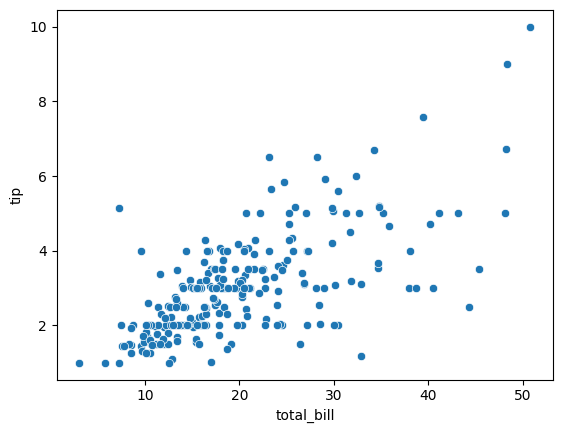

In [ ]:
sns.scatterplot(data=tips_df, x='total_bill', y='tip')

<Axes: xlabel='total_bill', ylabel='tip'>

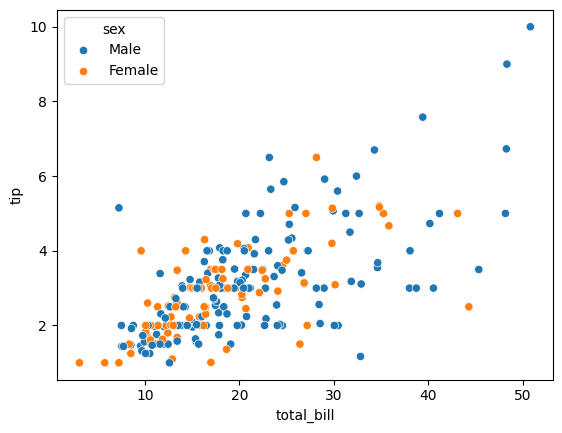

In [ ]:
sns.color_palette(palette='Pastel1')
sns.scatterplot(data=tips_df, x='total_bill', y='tip', hue='sex')


<Axes: xlabel='total_bill', ylabel='day'>

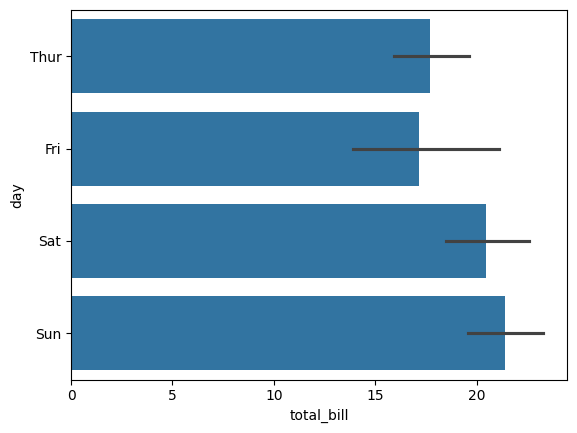

In [ ]:
sns.barplot(data=tips_df, x= 'total_bill', y='day') 

(1.0, 3.0)

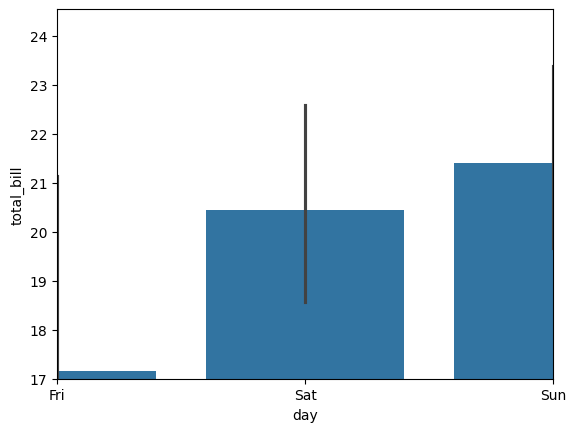

In [ ]:
sns.barplot(data=tips_df, x= 'day', y='total_bill') 
plt.ylim(17)
plt.xlim(1,3)

In [ ]:
tips_df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='day', ylabel='total_bill'>

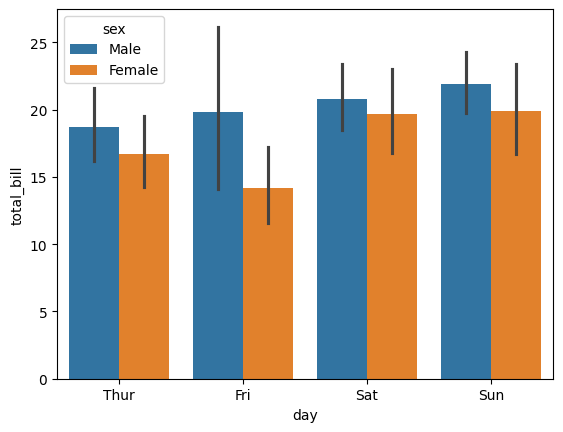

In [ ]:
sns.barplot(data=tips_df, hue='sex', x= 'day', y='total_bill') 
#sns.scatterplot(data=tips_df, hue='size', x= 'day', y='total_bill') 

<Axes: xlabel='total_bill', ylabel='Count'>

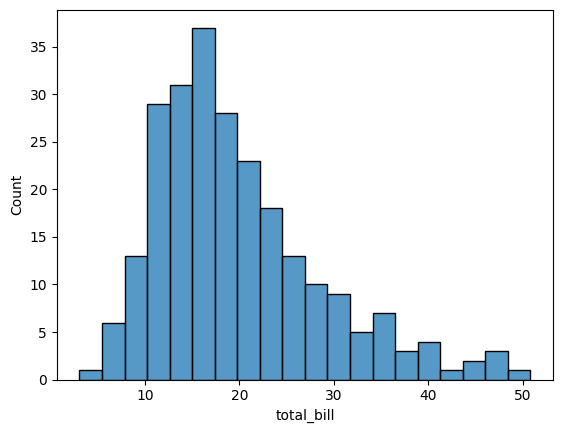

In [ ]:

sns.histplot(data=tips_df, x='total_bill', bins=20)


In [ ]:
import os
os.listdir('../../../../../')

['All Users', 'Default', 'Default User', 'desktop.ini', 'Marti', 'Public']

In [ ]:
left_df = pd.DataFrame({ 'key' : ['K1', 'k2', 'K3' , 'K4', 'K5'],
            'A' : ['A1', 'A2', 'A3', 'A4','A5'],
            'B' : ['B1', 'B2', 'B3', 'B4','B5']
})

In [ ]:
left_df

,key,A,B
0,K1,A1,B1
1,k2,A2,B2
2,K3,A3,B3
3,K4,A4,B4
4,K5,A5,B5


In [ ]:
right_df = pd.DataFrame( { 'key' : ['K1', 'k2', 'K3' , 'K4'],
            'C' : ['C1', 'C2', 'C3', 'C4'],
            'D' : ['D1', 'D2', 'D3', 'D4']
})

In [ ]:
right_df

,key,C,D
0,K1,C1,D1
1,k2,C2,D2
2,K3,C3,D3
3,K4,C4,D4


In [ ]:
pd.merge(left_df, right_df, on='key' , how='left') 

,key,A,B,C,D
0,K1,A1,B1,C1,D1
1,k2,A2,B2,C2,D2
2,K3,A3,B3,C3,D3
3,K4,A4,B4,C4,D4
4,K5,A5,B5,NaN,NaN


In [ ]:
pd.merge(left_df, right_df, how='cross') 

,key_x,A,B,key_y,C,D
0,K1,A1,B1,K1,C1,D1
1,K1,A1,B1,k2,C2,D2
2,K1,A1,B1,K3,C3,D3
3,K1,A1,B1,K4,C4,D4
4,k2,A2,B2,K1,C1,D1
5,k2,A2,B2,k2,C2,D2
6,k2,A2,B2,K3,C3,D3
7,k2,A2,B2,K4,C4,D4
8,K3,A3,B3,K1,C1,D1
9,K3,A3,B3,k2,C2,D2


In [60]:
import pandas as pd
import requests

url = "https://sv.wikipedia.org/wiki/Sveriges_demografi"
 

In [61]:

 
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36"}
 

In [62]:
resp = requests.get(url, headers=headers, timeout=30)

In [90]:
dfs = pd.read_html(resp.text)
print(len(dfs))

21


C:\Users\Marti\AppData\Local\Temp\ipykernel_27320\1463905647.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  dfs = pd.read_html(resp.text)


In [91]:
dfs[10]

,0,1
0,Statsskick,Grundlag · Statschef · Riksdag · Regering · La...
1,NaN,NaN
2,Försvar,Totalförsvaret(Totalförsvarsplikt · Civilplikt...
3,NaN,NaN
4,Politik,Politiska partier · Politiska unioner · Europa...
5,NaN,NaN
6,Rättsväsen,Säkerhetspolis · Polis · Domstolsväsende
7,NaN,NaN
8,Administration,Svenska staten · Myndigheter · Län · Kommuner ...


In [95]:
dfs[2]

,Civilstånd 31 december 2016,Antal,Andel (%),Varav män,Kvinnor
0,Ogifta,5 257 563,5260,2 820 248,2 437 315
1,Gifta,3 329 589,3331,1 672 460,1 657 129
2,Skilda,967 638,968,420 985,546 653
3,Änkor/änklingar,440 363,441,99 654,340 709


In [99]:
import plotly.express as px

fig = px.scatter ( x = [1,2,3,4,5], y = [6,7,8,9,10])

fig

In [120]:
gapminder_df = px.data.gapminder()

gapminder_df.head(25)

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4
5,Afghanistan,Asia,1977,38.438,14880372,786.113360,AFG,4
6,Afghanistan,Asia,1982,39.854,12881816,978.011439,AFG,4
7,Afghanistan,Asia,1987,40.822,13867957,852.395945,AFG,4
8,Afghanistan,Asia,1992,41.674,16317921,649.341395,AFG,4
9,Afghanistan,Asia,1997,41.763,22227415,635.341351,AFG,4


In [121]:
gapminder_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB


In [123]:
gapminder_df.isnull().info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   country    1704 non-null   bool 
 1   continent  1704 non-null   bool 
 2   year       1704 non-null   bool 
 3   lifeExp    1704 non-null   bool 
 4   pop        1704 non-null   bool 
 5   gdpPercap  1704 non-null   bool 
 6   iso_alpha  1704 non-null   bool 
 7   iso_num    1704 non-null   bool 
dtypes: bool(8)
memory usage: 13.4 KB


In [148]:
gapminder_df['country'].unique()

array(['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina',
       'Australia', 'Austria', 'Bahrain', 'Bangladesh', 'Belgium',
       'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil',
       'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon',
       'Canada', 'Central African Republic', 'Chad', 'Chile', 'China',
       'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.',
       'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Czech Republic',
       'Denmark', 'Djibouti', 'Dominican Republic', 'Ecuador', 'Egypt',
       'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Ethiopia',
       'Finland', 'France', 'Gabon', 'Gambia', 'Germany', 'Ghana',
       'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Haiti',
       'Honduras', 'Hong Kong, China', 'Hungary', 'Iceland', 'India',
       'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy',
       'Jamaica', 'Japan', 'Jordan', 'Kenya', 'Korea, Dem. Rep.',
       'Korea, Rep.', 'Kuwait', 'Leba

In [127]:
gapminder_df['year'].unique()

array([1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, 2002,
       2007])

In [134]:
gapminder_df['country'].value_counts()

country
Afghanistan           12
Albania               12
Algeria               12
Angola                12
Argentina             12
                      ..
Vietnam               12
West Bank and Gaza    12
Yemen, Rep.           12
Zambia                12
Zimbabwe              12
Name: count, Length: 142, dtype: int64

In [135]:
sweden = gapminder_df['country'] == 'Sweden'

In [144]:
sweden_df = gapminder_df[sweden].reset_index(drop= True)

In [145]:
sweden_df

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Sweden,Europe,1952,71.860,7124673,8527.844662,SWE,752
1,Sweden,Europe,1957,72.490,7363802,9911.878226,SWE,752
2,Sweden,Europe,1962,73.370,7561588,12329.441920,SWE,752
3,Sweden,Europe,1967,74.160,7867931,15258.296970,SWE,752
4,Sweden,Europe,1972,74.720,8122293,17832.024640,SWE,752
5,Sweden,Europe,1977,75.440,8251648,18855.725210,SWE,752
6,Sweden,Europe,1982,76.420,8325260,20667.381250,SWE,752
7,Sweden,Europe,1987,77.190,8421403,23586.929270,SWE,752
8,Sweden,Europe,1992,78.160,8718867,23880.016830,SWE,752
9,Sweden,Europe,1997,79.390,8897619,25266.594990,SWE,752


In [173]:
nordic = ['Sweden', 'Norway']
nordic_d = gapminder_df['country'].isin(nordic)     

nordic_df =gapminder_df[nordic_df]

In [152]:
fig = px.scatter(gapminder_df, x='gdpPercap', y = 'lifeExp',title = 'Life xpensety vs gdp per capita')
fig.show()

In [156]:
fig = px.scatter(sweden_df, x='gdpPercap', y = 'lifeExp',title = 'Sweden Life xpensety vs gdp per capita')
fig

In [ ]:
gapminder_df.head()

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


In [162]:
fig = px.scatter(gapminder_df, x='gdpPercap', y = 'lifeExp',title = 'Life xpensety vs gdp per capita', color = 'continent', size = 'pop', log_x=True)
fig

In [160]:
fig = px.scatter(gapminder_df, x='gdpPercap', y = 'lifeExp',title = 'Life xpensety vs gdp per capita', color = 'continent', log_x = True)
fig

In [165]:
fig = px.line(sweden_df, x='year',y='lifeExp')
fig.show()

In [183]:
fig = px.line(nordic_df, x = 'year' , y = 'lifeExp', color='country',title= 'hej')
fig.show()                                                          

In [ ]:
def pr
    for lön in df:
        if df['salary'] <